# Klasifikasi Multilabel: Pelabelan Atribut Prompt

**Dataset:** `master_dataset.csv` (1.859 prompt, gabungan dari `clean`, `real`, `augment`, `balance`, `noisy`). Tiap prompt memiliki **5 sampai 8 label** dari 23 label yang menggambarkan: tingkat kesulitan, domain, biaya, panjang jawaban, tingkat penalaran, dan mode penggunaan.

**Tujuan:** memprediksi seluruh kumpulan label dari teks prompt (misalnya untuk **routing prompt** ke model yang sesuai biaya dan kemampuannya).

**Pertanyaan:**
1. Bagaimana struktur label (apakah ada kelompok label)?
2. Seberapa akurat model memprediksi setiap kelompok?
3. Apakah skor yang tinggi benar-benar mencerminkan kemampuan menggeneralisasi, atau ada kebocoran data?

In [1]:
import glob, os
def cari(nama):
    # cari file di folder ini maupun subfolder
    h = glob.glob('**/'+nama, recursive=True)
    assert h, f"File {nama} tidak ditemukan di {os.getcwd()}"
    return h[0]
from sklearn.metrics import f1_score, hamming_loss, precision_score, recall_score, accuracy_score
def ringkas(Y, P):
    return dict(F1_micro=f1_score(Y,P,average='micro',zero_division=0), F1_macro=f1_score(Y,P,average='macro',zero_division=0),
                F1_samples=f1_score(Y,P,average='samples',zero_division=0), Hamming_loss=hamming_loss(Y,P), Subset_acc=accuracy_score(Y,P))
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, ast, collections
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline, make_union
from sklearn.model_selection import train_test_split
sns.set_theme(style='whitegrid')
df = pd.read_csv(cari('master_dataset.csv'))
print(df.shape); df.head()

(1859, 2)


,prompt,labels
0,i'm trying to reverse binary tree in postgres ...,"[""coding"", ""medium-output"", ""moderate"", ""inter..."
1,gcp cors error help,"[""debugging"", ""short-output"", ""moderate"", ""int..."
2,npm clear cache force,"[""moderate"", ""cheap"", ""short-output"", ""realtim..."
3,write a middleware for logging requests in exp...,"[""moderate"", ""balanced"", ""medium-output"", ""int..."
4,how do i write a regex to parse emails using g...,"[""coding"", ""medium-output"", ""moderate"", ""inter..."


## 1. Pembersihan dan Pemahaman Data

Missing: 0 | prompt duplikat: 0
Jumlah label per prompt: {5: 340, 6: 1289, 7: 209, 8: 21}


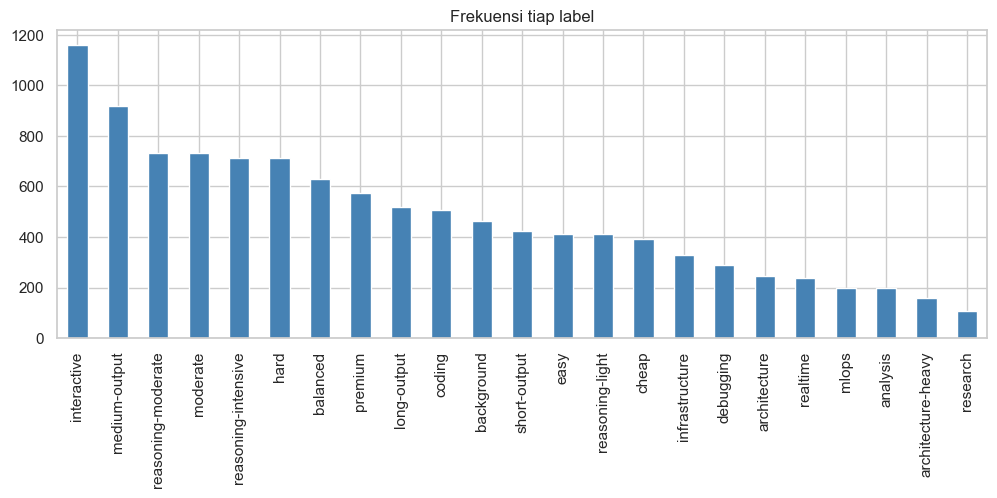

Jumlah label unik: 23


In [2]:
# format kolom labels campuran: sebagian JSON ["a"], sebagian gaya Python ['a'] -> ast.literal_eval membaca keduanya
df['L'] = df['labels'].apply(ast.literal_eval)
df['prompt'] = df['prompt'].str.replace(r'\s+',' ',regex=True).str.strip()
print('Missing:', df.isna().sum().sum(), '| prompt duplikat:', df.prompt.duplicated().sum())
print('Jumlah label per prompt:', df.L.apply(len).value_counts().sort_index().to_dict())
cnt = pd.Series(collections.Counter(x for l in df.L for x in l)).sort_values(ascending=False)
cnt.plot.bar(figsize=(12,4), color='steelblue', title='Frekuensi tiap label'); plt.show()
print('Jumlah label unik:', len(cnt))

**Temuan:** ada **23 label unik**, setiap prompt memiliki 5-8 label (rata-rata sekitar 6). Kolom `labels` ternyata berformat campuran (500 baris memakai tanda kutip tunggal) sehingga harus dibaca dengan `ast.literal_eval`, bukan `json.loads`. Selain itu beberapa prompt mengandung *noise* (kata berulang seperti "standard standard", tanda kutip nyasar).

In [3]:
# Label ternyata membentuk kelompok atribut
GRUP = {
 'kesulitan': ['easy','moderate','hard'],
 'biaya': ['cheap','balanced','premium'],
 'panjang_jawaban': ['short-output','medium-output','long-output'],
 'penalaran': ['reasoning-light','reasoning-moderate','reasoning-intensive'],
 'mode': ['interactive','background','realtime'],
 'domain': ['coding','debugging','architecture','architecture-heavy','infrastructure','analysis','mlops','research'],
}
for g,ls in GRUP.items():
    n = df.L.apply(lambda l: sum(x in ls for x in l))
    print(f'{g:16s} label per prompt -> {n.value_counts().sort_index().to_dict()}')

kesulitan        label per prompt -> {1: 1859}
biaya            label per prompt -> {0: 268, 1: 1589, 2: 2}
panjang_jawaban  label per prompt -> {1: 1859}
penalaran        label per prompt -> {1: 1859}
mode             label per prompt -> {0: 58, 1: 1741, 2: 60}
domain           label per prompt -> {0: 105, 1: 1494, 2: 240, 3: 20}


**Temuan penting:** *kesulitan*, *panjang jawaban*, dan *penalaran* selalu **tepat 1 label per prompt** (100%). *Mode* 1 label pada ± 94% prompt dan *biaya* pada ± 85%; sisanya tidak memiliki label di kelompok itu. Kelompok **domain** paling bervariasi: 0 label (105 prompt), 1 (1.494), 2 (240), dan 3 (20). Jadi dataset ini campuran: beberapa dimensi berperilaku seperti multikelas, dan hanya dimensi domain yang benar-benar multilabel.

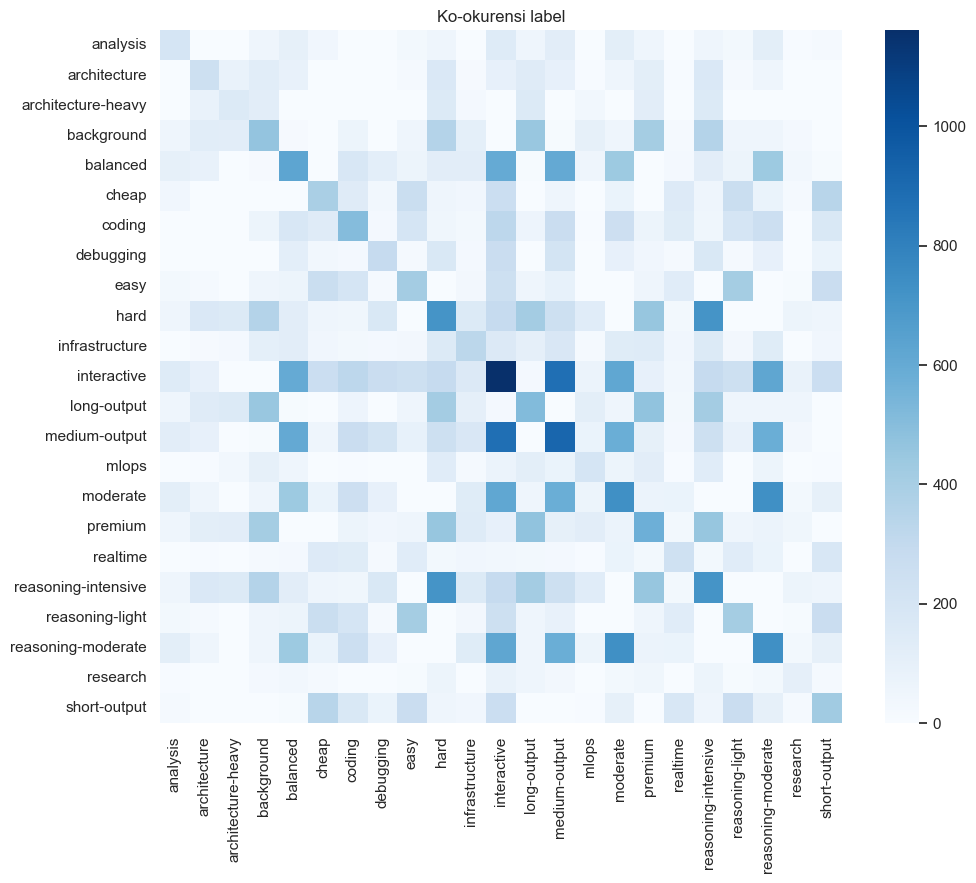

In [4]:
mlb = MultiLabelBinarizer(); Y = mlb.fit_transform(df.L); LAB = list(mlb.classes_)
co = pd.DataFrame(Y.T@Y, index=LAB, columns=LAB)
plt.figure(figsize=(11,9)); sns.heatmap(co.loc[LAB,LAB], cmap='Blues'); plt.title('Ko-okurensi label'); plt.show()

## 2. Pembagian Data dan Fitur

In [5]:
Xtr, Xte, Ytr, Yte = train_test_split(df.prompt, Y, test_size=0.2, random_state=42)
vec = make_union(TfidfVectorizer(ngram_range=(1,2), min_df=1, sublinear_tf=True, lowercase=True),
                 TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5), min_df=2, sublinear_tf=True))
Atr = vec.fit_transform(Xtr); Ate = vec.transform(Xte)
print('Latih/uji:', Atr.shape[0], Ate.shape[0], '| fitur:', Atr.shape[1])

Latih/uji: 1487 372 | fitur: 21832


Fitur gabungan **TF-IDF kata** (1-2 kata) dan **TF-IDF karakter** (2-5 karakter). N-gram karakter membantu pada teks pendek dan *noisy* (salah ketik, kata berulang) karena tidak bergantung pada kata utuh.

## 3. Pemodelan

In [6]:
# Baseline: selalu memprediksi label yang muncul pada >50% prompt di data latih
base = np.tile((Ytr.mean(0)>0.5).astype(int), (len(Yte),1))
models = {
 'Logistic Regression': OneVsRestClassifier(LogisticRegression(C=20, max_iter=2000)),
 'Linear SVM': OneVsRestClassifier(LinearSVC(C=1)),
}
skor = {'Baseline (label dominan)': ringkas(Yte, base)}; pred = {}
for n,m in models.items():
    m.fit(Atr, Ytr); pred[n] = m.predict(Ate); skor[n] = ringkas(Yte, pred[n])
pd.DataFrame(skor).T.round(4)

,F1_micro,F1_macro,F1_samples,Hamming_loss,Subset_acc
Baseline (label dominan),0.1788,0.0332,0.1820,0.2470,0.0000
Logistic Regression,0.8209,0.7937,0.8100,0.0877,0.4194
Linear SVM,0.8278,0.8059,0.8205,0.0853,0.4328


**Cara membaca:** *Baseline* menunjukkan seberapa baik model yang sama sekali tidak membaca teks. Model yang berguna harus mengungguli baseline dengan jelas, terutama pada **F1-macro** (semua label sama penting) dan **Subset accuracy** (semua label benar sekaligus).

In [7]:
best = max(models, key=lambda k: skor[k]['F1_macro']); P = pred[best]
print('Model terbaik:', best)
dfp = pd.DataFrame({'label':LAB,'jumlah_uji':Yte.sum(0),'precision':precision_score(Yte,P,average=None,zero_division=0),
                    'recall':recall_score(Yte,P,average=None,zero_division=0),'F1':f1_score(Yte,P,average=None,zero_division=0)}).set_index('label')
dfp.sort_values('F1').round(3)

Model terbaik: Linear SVM


,jumlah_uji,precision,recall,F1
label,,,,
architecture,43,0.686,0.558,0.615
infrastructure,77,0.857,0.545,0.667
analysis,41,0.828,0.585,0.686
realtime,48,0.769,0.625,0.690
balanced,122,0.725,0.713,0.719
cheap,90,0.818,0.700,0.754
reasoning-moderate,140,0.759,0.764,0.762
moderate,140,0.764,0.764,0.764
easy,96,0.833,0.729,0.778


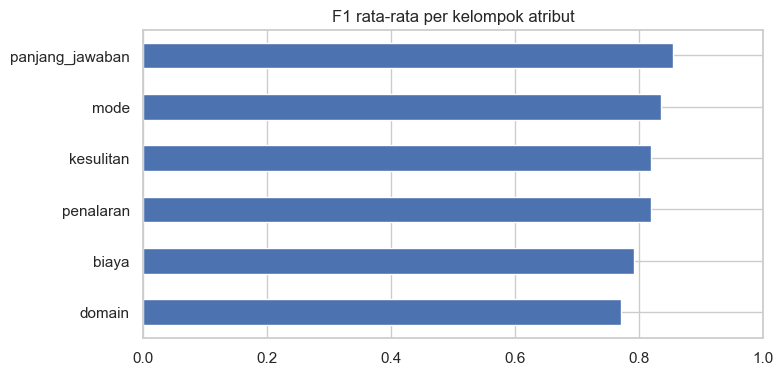

kesulitan          0.820
biaya              0.793
panjang_jawaban    0.854
penalaran          0.819
mode               0.835
domain             0.772
dtype: float64

In [8]:
# F1 rata-rata per kelompok atribut
rows = {g: dfp.loc[ls,'F1'].mean() for g,ls in GRUP.items()}
pd.Series(rows).sort_values().plot.barh(figsize=(8,4), title='F1 rata-rata per kelompok atribut'); plt.xlim(0,1); plt.show()
pd.Series(rows).round(3)

**Temuan:** kelompok dengan F1 tertinggi adalah **panjang jawaban (± 0,85)** dan **mode (± 0,84)**, lalu kesulitan dan penalaran (± 0,82). Justru **domain paling rendah (± 0,77)**, dengan label *architecture* (F1 ± 0,62), *infrastructure* (± 0,67), dan *analysis* (± 0,69) paling sulit. Kemungkinan penyebabnya: domain-domain ini saling tumpang tindih (misalnya *architecture* vs *architecture-heavy* vs *infrastructure*) dan sebuah prompt bisa punya 0-3 label domain tanpa aturan yang jelas. Sebaliknya *hard*, *reasoning-intensive*, *mlops*, dan *premium* paling mudah (F1 > 0,90).

## 4. Apakah Skor Ini Dapat Dipercaya? (Pengecekan Kebocoran Data)

In [9]:
# kelompokkan prompt uji berdasarkan file sumber (clean.csv / noisy.csv / lainnya) dan ukur kemiripannya dengan data latih
noisy = set(pd.read_csv(cari('noisy.csv')).prompt.str.replace(r'\s+',' ',regex=True).str.strip())
clean = set(pd.read_csv(cari('clean.csv')).prompt.str.replace(r'\s+',' ',regex=True).str.strip())
cek = pd.DataFrame({'prompt':Xte.values}); cek['sumber'] = np.where(cek.prompt.isin(noisy),'noisy',np.where(cek.prompt.isin(clean),'clean','lainnya'))
from sklearn.metrics.pairwise import cosine_similarity
cv = TfidfVectorizer(analyzer='char_wb', ngram_range=(3,5)).fit(Xtr)
cek['kemiripan_maks'] = cosine_similarity(cv.transform(Xte), cv.transform(Xtr)).max(1)
out = {}
for s in ['clean','noisy','lainnya']:
    m = (cek.sumber==s).values
    r = ringkas(Yte[m], P[m]); r['n'] = int(m.sum()); r['%mirip>0.8'] = float((cek.kemiripan_maks[m]>0.8).mean()); out[s] = r
pd.DataFrame(out).T[['n','F1_micro','F1_macro','Subset_acc','%mirip>0.8']].round(3)

,n,F1_micro,F1_macro,Subset_acc,%mirip>0.8
clean,36.0,1.000,0.913,1.000,0.944
noisy,66.0,0.997,0.899,0.985,0.636
lainnya,270.0,0.763,0.693,0.222,0.022


**Temuan penting (kebocoran data):** prompt dari `clean.csv` dan `noisy.csv` dibuat dari **templat yang sama**, dan `noisy` pada dasarnya versi berisik dari kalimat serupa. Akibatnya, hampir semua prompt uji dari kedua sumber ini (± 94% *clean* dan ± 64% *noisy*) punya **kembaran yang nyaris identik di data latih** akibat pembagian acak. Itulah sebabnya skornya hampir sempurna (F1 ± 1,0), dan ini **bukan** bukti bahwa model kuat atau bahwa teks *noisy* mudah. Prompt dari sumber lain hanya ± 2% yang punya kembaran, dan di sana F1-micro turun menjadi **± 0,76** dengan *subset accuracy* hanya ± 0,22. Angka itulah perkiraan yang lebih jujur untuk prompt baru.

In [10]:
# contoh prediksi
for i in np.random.RandomState(3).choice(len(Xte), 4, replace=False):
    print('Prompt  :', Xte.iloc[i][:120]); print('Asli    :', sorted([l for l,v in zip(LAB,Yte[i]) if v])); print('Prediksi:', sorted([l for l,v in zip(LAB,P[i]) if v]),'\n')

Prompt  : I'm trying to read file async in azure but this isn't working: ``` def func(): pass ``` Can you rewrite it?
Asli    : ['coding', 'interactive', 'medium-output', 'moderate', 'reasoning-moderate']
Prediksi: ['coding', 'interactive', 'medium-output', 'moderate', 'reasoning-moderate'] 

Prompt  : How to make a GET request with curl
Asli    : ['cheap', 'easy', 'interactive', 'reasoning-light', 'short-output']
Prediksi: ['balanced', 'coding', 'easy', 'interactive', 'medium-output', 'reasoning-light'] 

Prompt  : parse json kafka
Asli    : ['coding', 'easy', 'realtime', 'reasoning-light', 'short-output']
Prediksi: ['coding', 'easy', 'realtime', 'reasoning-light', 'short-output'] 

Prompt  : produce a 100 row csv of fake weather data
Asli    : ['analysis', 'background', 'easy', 'long-output', 'premium', 'reasoning-light']
Prediksi: ['background', 'coding', 'easy', 'long-output', 'premium', 'reasoning-light'] 



## 5. Kesimpulan
- Dataset terdiri dari **23 label** dengan 5-8 label per prompt; label membentuk **kelompok atribut** (kesulitan, biaya, panjang jawaban, penalaran, mode, domain). Kecuali domain, tiap kelompok pada dasarnya satu pilihan per prompt.
- Model TF-IDF (kata + karakter) dengan One-vs-Rest (Linear SVM terbaik) jauh melampaui baseline: F1-micro ± 0,83 vs ± 0,18 dan F1-macro ± 0,81 vs ± 0,03 pada keseluruhan data uji.
- **Skor keseluruhan terlalu optimistis** karena kebocoran: prompt *clean* dan *noisy* yang berasal dari templat sama muncul di data latih maupun uji. Pada prompt tanpa kembaran, F1-micro hanya ± 0,76 dan *subset accuracy* ± 0,22.
- Atribut **panjang jawaban** dan **mode** paling mudah diprediksi; **domain** paling sulit (label *architecture*, *infrastructure*, *analysis*), kemungkinan karena definisinya tumpang tindih.
- Dataset kecil (1.859 baris) dan sebagian dihasilkan secara semi-otomatis, sehingga hasil belum tentu berlaku pada prompt nyata pengguna.
- **Saran:** bagi data berdasarkan templat/kelompok (*group split*) agar versi *clean* dan *noisy* dari kalimat yang sama tidak terpisah antara latih dan uji.
- **Saran:** karena banyak kelompok bersifat pilihan tunggal, memodelkannya sebagai beberapa klasifikasi multikelas (satu per kelompok) bisa lebih tepat daripada 23 klasifikasi biner independen.